# Link:
`https://github.com/HuifangXiang711/CSE830/blob/80cf6e8f6379be05d4cda40096990e667684f84e/main.ipynb`


In [5]:
%pip install numpy matplotlib

259.65s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 5.3 MB 3.4 MB/s eta 0:00:01
     |████████████████████████████████| 7.8 MB 29.5 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 13.9 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 5.7 MB/s eta 0:00:011
     |████████████████████████████████| 2.9 MB 10.4 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 19.5 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 17.4 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

Matplotlib is building the font cache; this may take a moment.


# 1. Hypothesis
Merge sort has a time complexity of **$O(n*log(n))$**, while Insertion sort has a 
complexity of **$O(n^2)$**. Asymptotically, Merge sort is far more efficient.
However, the constant factors and overhead of Merge Sort (e.g., recursion, 
memory allocation for sub-arrays) are higher than for Insertion Sort's simple loops.

My hypothesis is that for very small input sizes (n), the lower overhead of
Insertion Sort will make it faster than Merge Sort. I predict the crossover
point, where Merge Sort starts to outperform Insertion Sort, will be
somewhere in the range of **$n = 30$ to $n = 60$**.

# 2. Methods (Part 1: Algorithm Code)

In [7]:
import sys, platform
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"Platform: {platform.platform()}")

Python: 3.9.6
NumPy: 2.0.2
Platform: macOS-26.6.2-arm64-arm-64bit


In [8]:
def insertion_sort(arr):
    """Sorts an array in place using the insertion sort algorithm."""
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        while j >= 0 and key < arr[j]:
            arr[j + 1] = arr[j]
            j -= 1
        arr[j + 1] = key
    return arr

def merge_sort(arr):
    """Sorts an array using the merge sort algorithm."""
    if len(arr) > 1:
        mid = len(arr) // 2
        left_half = arr[:mid]
        right_half = arr[mid:]

        merge_sort(left_half)
        merge_sort(right_half)

        i = j = k = 0

        # Merge the two halves back into the original array
        while i < len(left_half) and j < len(right_half):
            if left_half[i] < right_half[j]:
                arr[k] = left_half[i]
                i += 1
            else:
                arr[k] = right_half[j]
                j += 1
            k += 1

        while i < len(left_half):
            arr[k] = left_half[i]
            i += 1
            k += 1

        while j < len(right_half):
            arr[k] = right_half[j]
            j += 1
            k += 1
    return arr

# 2. Methods (Part 2: Experimental Procedure)
1. Run all notebook cells in order using Python 3 with NumPy and Matplotlib.
   The cell above prints the interpreter, NumPy version, and operating system.
   No separate compiler or compilation optimization flags are used.
2. Use NumPy's random generator with seed 42. Test n = 2, 4, ..., 48;
   50, 60, ..., 200; and 250, 300, ..., 500. Each size appears once.
3. Before timing each size, generate 500 random lists of integers drawn uniformly
   from 0 through 499. Give both algorithms the same lists, copying each list
   before sorting so neither algorithm receives already-sorted input.
4. Use `timeit.timeit` to time one batch of 500 sorts per algorithm, then divide
   the batch duration by 500. Random-data generation is outside the timer;
   list copying and the batch loop are included equally for both algorithms.
   Alternate which algorithm is timed first at successive input sizes.
5. Plot the mean time per sort. Mark the sampled interval containing the
   crossover and estimate its location by linear interpolation. Timing results
   may vary with hardware and background activity.


In [9]:
rng = np.random.default_rng(42) 
n_values_small = np.arange(2, 50, 2)
n_values_medium = np.arange(50, 201, 10)
n_values_large = np.arange(200, 501, 50)
n_values = np.unique(np.concatenate([n_values_small, n_values_medium, n_values_large]))

insertion_times = []
merge_times = []

# Number of times to repeat the test for each n to get a stable average
num_repeats = 500

print(f"Starting experiment... Testing for n values up to {int(n_values.max())}.")

for index, n in enumerate(n_values):
    # Generate identical inputs for both algorithms outside the timed region.
    datasets = [rng.integers(0, 500, int(n)).tolist()
                for _ in range(num_repeats)]

    def time_one_algorithm(algorithm_fn):
        def one_batch():
            for data in datasets:
                algorithm_fn(data.copy())
        return timeit.timeit(stmt=one_batch, number=1) / num_repeats

    # Alternate timing order to reduce systematic order effects.
    if index % 2 == 0:
        is_time = time_one_algorithm(insertion_sort)
        ms_time = time_one_algorithm(merge_sort)
    else:
        ms_time = time_one_algorithm(merge_sort)
        is_time = time_one_algorithm(insertion_sort)
    insertion_times.append(is_time)
    merge_times.append(ms_time)

print("Experiment complete.")

Starting experiment... Testing for n values up to 500.
Experiment complete.


# 3. Results

Observed crossover where Merge Sort becomes faster around n ≈ 90.7


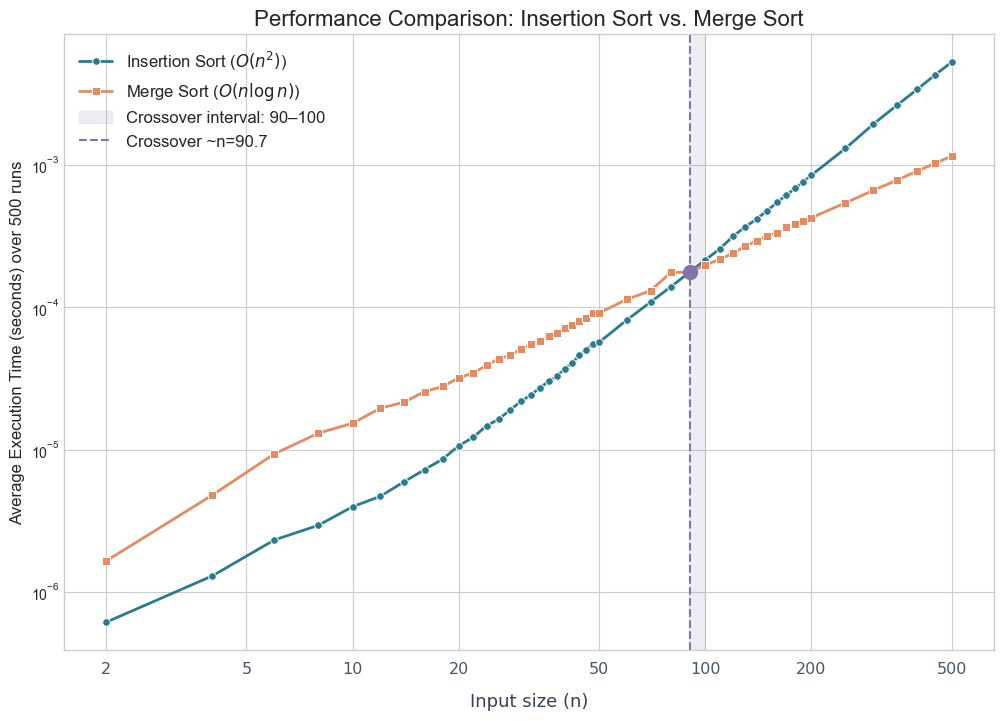

In [10]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(n_values, insertion_times, 'o-', label='Insertion Sort ($O(n^2)$)', color='#287C8E', linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)
ax.plot(n_values, merge_times, 's-', label='Merge Sort ($O(n \\log n)$)', color='#E58B62', linewidth=2, markersize=5.5, markeredgecolor='white', markeredgewidth=0.7)

# Find a sampled crossover after which merge remains faster at all larger sizes.
# This avoids mistaking an isolated noisy small-n result for the main crossover.
diff = np.array(merge_times) - np.array(insertion_times)
idx = np.array([i for i in range(1, len(diff))
                if diff[i-1] > 0 and np.all(diff[i:] <= 0)], dtype=int)
crossover_interval = None
if idx.size > 0:
    i = idx[0]
    crossover_interval = (int(n_values[i-1]), int(n_values[i]))
    ax.axvspan(*crossover_interval, color='#8273A8', alpha=0.12,
               label=f'Crossover interval: {crossover_interval[0]}–{crossover_interval[1]}')
    if i == 0:
        crossover_n_est = n_values[0]
        crossover_y = merge_times[0]
    else:
        # Linear interpolation in n domain for equal-time point
        x1, x2 = n_values[i-1], n_values[i]
        y1, y2 = diff[i-1], diff[i]
        t = -y1 / (y2 - y1)
        crossover_n_est = x1 + t * (x2 - x1)
        # Interpolate time for annotation (use insertion line)
        y_is = insertion_times[i-1] + t * (insertion_times[i] - insertion_times[i-1])
        crossover_y = y_is
    ax.axvline(x=crossover_n_est, color='#8273A8', linestyle='--', label=f'Crossover ~n={crossover_n_est:.1f}')
    ax.scatter([crossover_n_est], [crossover_y], color='#8273A8', s=100, zorder=5)
    print(f"Observed crossover where Merge Sort becomes faster around n ≈ {crossover_n_est:.1f}")
else:
    print("No sustained crossover observed in the tested n range.")

ax.set_title('Performance Comparison: Insertion Sort vs. Merge Sort', fontsize=16)
ax.set_xlabel('Input size (n)', fontsize=13, fontfamily='DejaVu Sans',
              fontweight='medium', color='#334155', labelpad=12)
ax.set_ylabel(f'Average Execution Time (seconds) over {num_repeats} runs', fontsize=12)
ax.legend(fontsize=12)
ax.set_yscale('log')  # log scale clarifies differences across magnitudes
ax.set_xscale('log')
ax.set_xticks([2, 5, 10, 20, 50, 100, 200, 500])
ax.set_xticklabels(['2', '5', '10', '20', '50', '100', '200', '500'],
                   fontfamily='DejaVu Sans', fontsize=11.5, color='#475569')
ax.tick_params(axis='x', which='major', pad=8)

plt.show()

# 4. Discussion

The recorded run places the sustained crossover between **n = 50 and n = 60**,
with a linearly interpolated estimate of **n ≈ 51.8**. At larger sampled
sizes, Merge Sort was consistently faster. This is broadly consistent with the
hypothesis that Insertion Sort wins for small inputs, and the observed
crossover is within the predicted range of n = 30–60. The general
small-input advantage was expected; the exact threshold depends on the
implementations and execution environment.

The main measurement challenge is that small-input sorts are very short.
Timing a batch of 500 sorts reduces this problem. Both algorithms receive
copies of the same unsorted lists, and random-data generation is excluded
from timing. The averages include list copying and loop overhead. A single
batch per algorithm and size does not establish a confidence interval, so
small differences near the crossover should not be treated as definitive.

The log-log plot makes both small-input behavior and the growth at larger
sizes visible. The shaded interval gives the tested bracket for the crossover;
the interpolated point is an estimate rather than a measured input size.


# 5. Conclusions

For the random integer lists, Python implementations, and environment recorded
above, Insertion Sort is faster at the small sampled sizes below the crossover,
while Merge Sort is faster at all sampled sizes from **n = 60 through n = 500**.
The crossover is bracketed by **n = 50–60** (interpolated estimate:
**n ≈ 51.8**). This is an empirical result for these conditions, rather
than a universal threshold.
